In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models

import os
import time
import copy

In [2]:
# =============================================================================
# 1. ГИПЕРПАРАМЕТРЫ И НАСТРОЙКИ
# =============================================================================

# --- ИЗМЕНЕНИЕ 1: Параметры для EfficientNetB4 ---
IMG_SIZE = 380          # Рекомендованный размер для EfficientNetB4
BATCH_SIZE = 16         # Уменьшаем батч, чтобы избежать нехватки памяти GPU
RANDOM_SEED = 42

# Параметры обучения (оставляем прежними, они хорошо подобраны)
# Этап 1: Обучение только "головы"
NUM_EPOCHS_HEAD = 8
LR_HEAD = 0.0005

# Этап 2: Fine-tuning всей модели
NUM_EPOCHS_FT = 12
LR_FT = 5e-5

# Параметры модели
DROPOUT_RATE = 0.5

# =============================================================================
# 2. ПОДГОТОВКА ДАННЫХ (с новым IMG_SIZE)
# =============================================================================

# Трансформации теперь используют новый размер изображения
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Остальная часть подготовки данных остается без изменений
full_dataset = datasets.ImageFolder(root='/kaggle/input/tree-classification')
class_names = full_dataset.classes
num_classes = len(class_names)
print(f"Найдено {num_classes} классов.")

torch.manual_seed(RANDOM_SEED)
val_size = int(0.2 * len(full_dataset))
train_size = len(full_dataset) - val_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

train_dataset.dataset.transform = train_transforms
val_dataset.dataset.transform = val_transforms

dataloaders = {
    'train': DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=os.cpu_count()),
    'val': DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=os.cpu_count())
}
dataset_sizes = {'train': len(train_dataset), 'val': len(val_dataset)}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используется устройство: {device}")

Найдено 22 классов.
Используется устройство: cuda


In [16]:
# =============================================================================
# 3. ИНИЦИАЛИЗАЦИЯ МОДЕЛИ
# =============================================================================

# --- ИЗМЕНЕНИЕ 2: Загружаем предобученную модель EfficientNetB4 ---
weights = models.EfficientNet_B4_Weights.IMAGENET1K_V1
model = models.efficientnet_b4(weights=weights)

# Заменяем "голову" классификатора (этот код универсален и не меняется)
num_ftrs = model.classifier[1].in_features
model.classifier = nn.Sequential(
    nn.Dropout(p=DROPOUT_RATE, inplace=True),
    nn.Linear(num_ftrs, num_classes)
)
model = model.to(device)

# Функция потерь
criterion = nn.CrossEntropyLoss()

# =============================================================================
# 4. УНИВЕРСАЛЬНАЯ ФУНКЦИЯ ДЛЯ ОБУЧЕНИЯ (без изменений)
# =============================================================================

def train_model(model, criterion, optimizer, scheduler, num_epochs, model_save_name):
    start_time = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print(f"Эпоха {epoch+1}/{num_epochs}")
        print('-' * 15)
        for phase in ['train', 'val']:
            if phase == 'train': model.train()
            else: model.eval()

            running_loss, running_corrects = 0.0, 0
            for inputs, labels in dataloaders[phase]:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]
            print(f'{phase.capitalize():<5} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())
                torch.save(model.state_dict(), model_save_name)
                print(f"Сохранена новая лучшая модель в '{model_save_name}'!")
        
        scheduler.step()
        print(f"Текущий LR: {optimizer.param_groups[0]['lr']:.6f}\n")

    time_elapsed = time.time() - start_time
    print(f"Этап обучения завершен за {time_elapsed // 60:.0f}м {time_elapsed % 60:.0f}с")
    print(f"Лучшая точность на валидации: {best_acc:.4f}")
    model.load_state_dict(best_model_wts)
    return model

# =============================================================================
# 5. ЗАПУСК ПРОЦЕССА ОБУЧЕНИЯ
# =============================================================================
# --- ИЗМЕНЕНИЕ 3: Новое имя для файла модели ---
MODEL_SAVE_NAME = "best_tree_classifier_b4.pth"

# --- ЭТАП 1: Обучение "головы" ---
print("--- ЭТАП 1: Обучение 'головы' классификатора ---")
for param in model.parameters(): param.requires_grad = False
for param in model.classifier.parameters(): param.requires_grad = True
optimizer_head = optim.AdamW(model.classifier.parameters(), lr=LR_HEAD)
scheduler_head = lr_scheduler.StepLR(optimizer_head, step_size=4, gamma=0.1)
model = train_model(model, criterion, optimizer_head, scheduler_head, num_epochs=NUM_EPOCHS_HEAD, model_save_name=MODEL_SAVE_NAME)

# --- ЭТАП 2: Fine-tuning всей модели ---
print("\n--- ЭТАП 2: Fine-tuning всей модели с низким LR ---")
for param in model.parameters(): param.requires_grad = True
optimizer_ft = optim.AdamW(model.parameters(), lr=LR_FT)
scheduler_ft = lr_scheduler.StepLR(optimizer_ft, step_size=5, gamma=0.1)
model = train_model(model, criterion, optimizer_ft, scheduler_ft, num_epochs=NUM_EPOCHS_FT, model_save_name=MODEL_SAVE_NAME)

print("\nПолное обучение завершено!")

Найдено 22 классов.
Используется устройство: cuda


Downloading: "https://download.pytorch.org/models/efficientnet_b4_rwightman-23ab8bcd.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b4_rwightman-23ab8bcd.pth
100%|██████████| 74.5M/74.5M [00:00<00:00, 148MB/s] 


--- ЭТАП 1: Обучение 'головы' классификатора ---
Эпоха 1/8
---------------


/usr/local/lib/python3.11/dist-packages/PIL/Image.py:1043: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Train Loss: 3.0241 Acc: 0.1632
Val   Loss: 2.9322 Acc: 0.3836
Сохранена новая лучшая модель в 'best_tree_classifier_b4.pth'!
Текущий LR: 0.000500

Эпоха 2/8
---------------


...

/usr/local/lib/python3.11/dist-packages/PIL/Image.py:1043: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Train Loss: 1.0268 Acc: 0.7188
Val   Loss: 1.1951 Acc: 0.6404
Текущий LR: 0.000005

Эпоха 7/12
---------------


/usr/local/lib/python3.11/dist-packages/PIL/Image.py:1043: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Train Loss: 1.0038 Acc: 0.7299
Val   Loss: 1.2084 Acc: 0.6336
Текущий LR: 0.000005

Эпоха 8/12
---------------


KeyboardInterrupt: 

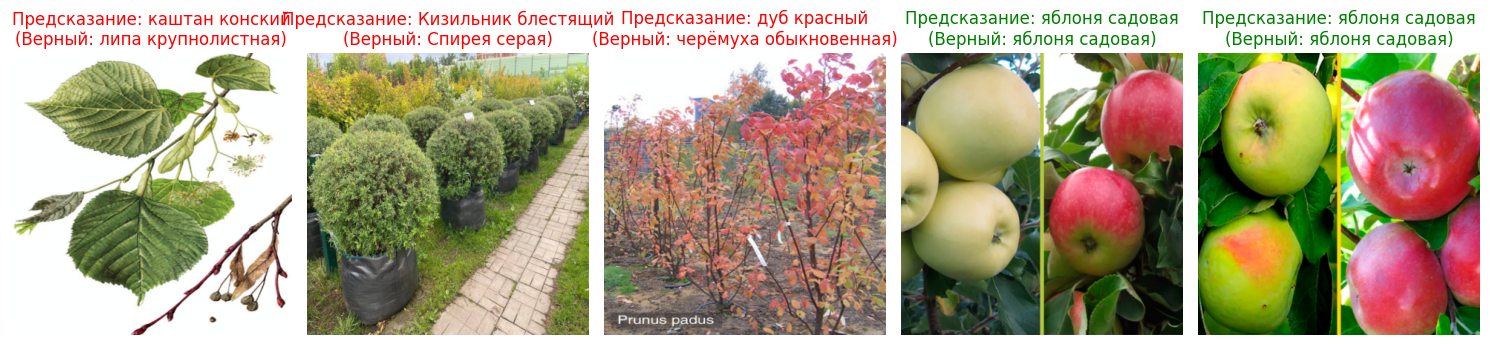

In [18]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_model_predictions(model, dataloader, class_names, num_images=5):
    """
    Отображает предсказания модели для нескольких изображений из датасета.
    """
    was_training = model.training
    model.eval()
    images_so_far = 0
    fig = plt.figure(figsize=(15, 8))

    with torch.no_grad():
        # Получаем один батч из валидационного загрузчика
        inputs, labels = next(iter(dataloader))
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Делаем предсказания
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)

        # Отображаем изображения и подписываем предсказания
        for j in range(inputs.size()[0]):
            if images_so_far < num_images:
                ax = plt.subplot(1, num_images, images_so_far + 1)
                
                # Отменяем нормализацию для отображения
                img = inputs.cpu().data[j].numpy().transpose((1, 2, 0))
                # Эти значения должны совпадать с теми, что вы использовали в transforms
                mean = np.array([0.485, 0.456, 0.406])
                std = np.array([0.229, 0.224, 0.225])
                img = std * img + mean
                img = np.clip(img, 0, 1)
                
                ax.imshow(img)
                ax.axis('off')
                
                predicted_label = class_names[preds[j]]
                true_label = class_names[labels[j]]
                
                # Устанавливаем цвет заголовка в зависимости от правильности предсказания
                title_color = 'green' if preds[j] == labels[j] else 'red'
                ax.set_title(f'Предсказание: {predicted_label}\n(Верный: {true_label})', color=title_color)

                images_so_far += 1
            else:
                break
        
        plt.tight_layout()
        plt.show()
        model.train(mode=was_training)


# --- Запуск визуализации ---

# 1. Убедимся, что загружены веса лучшей модели
# (Это было сделано в конце предыдущего скрипта, но на всякий случай)
model.load_state_dict(torch.load('/kaggle/working/best_tree_classifier_b4.pth'))

# 2. Получаем имена классов из объекта датасета
# Убедитесь, что переменная `val_dataset` доступна
class_names = val_dataset.dataset.classes 

# 3. Вызываем функцию
visualize_model_predictions(model, dataloaders['val'], class_names, num_images=5)


--- Построение confusion matrix для лучшей модели на валидационных данных ---


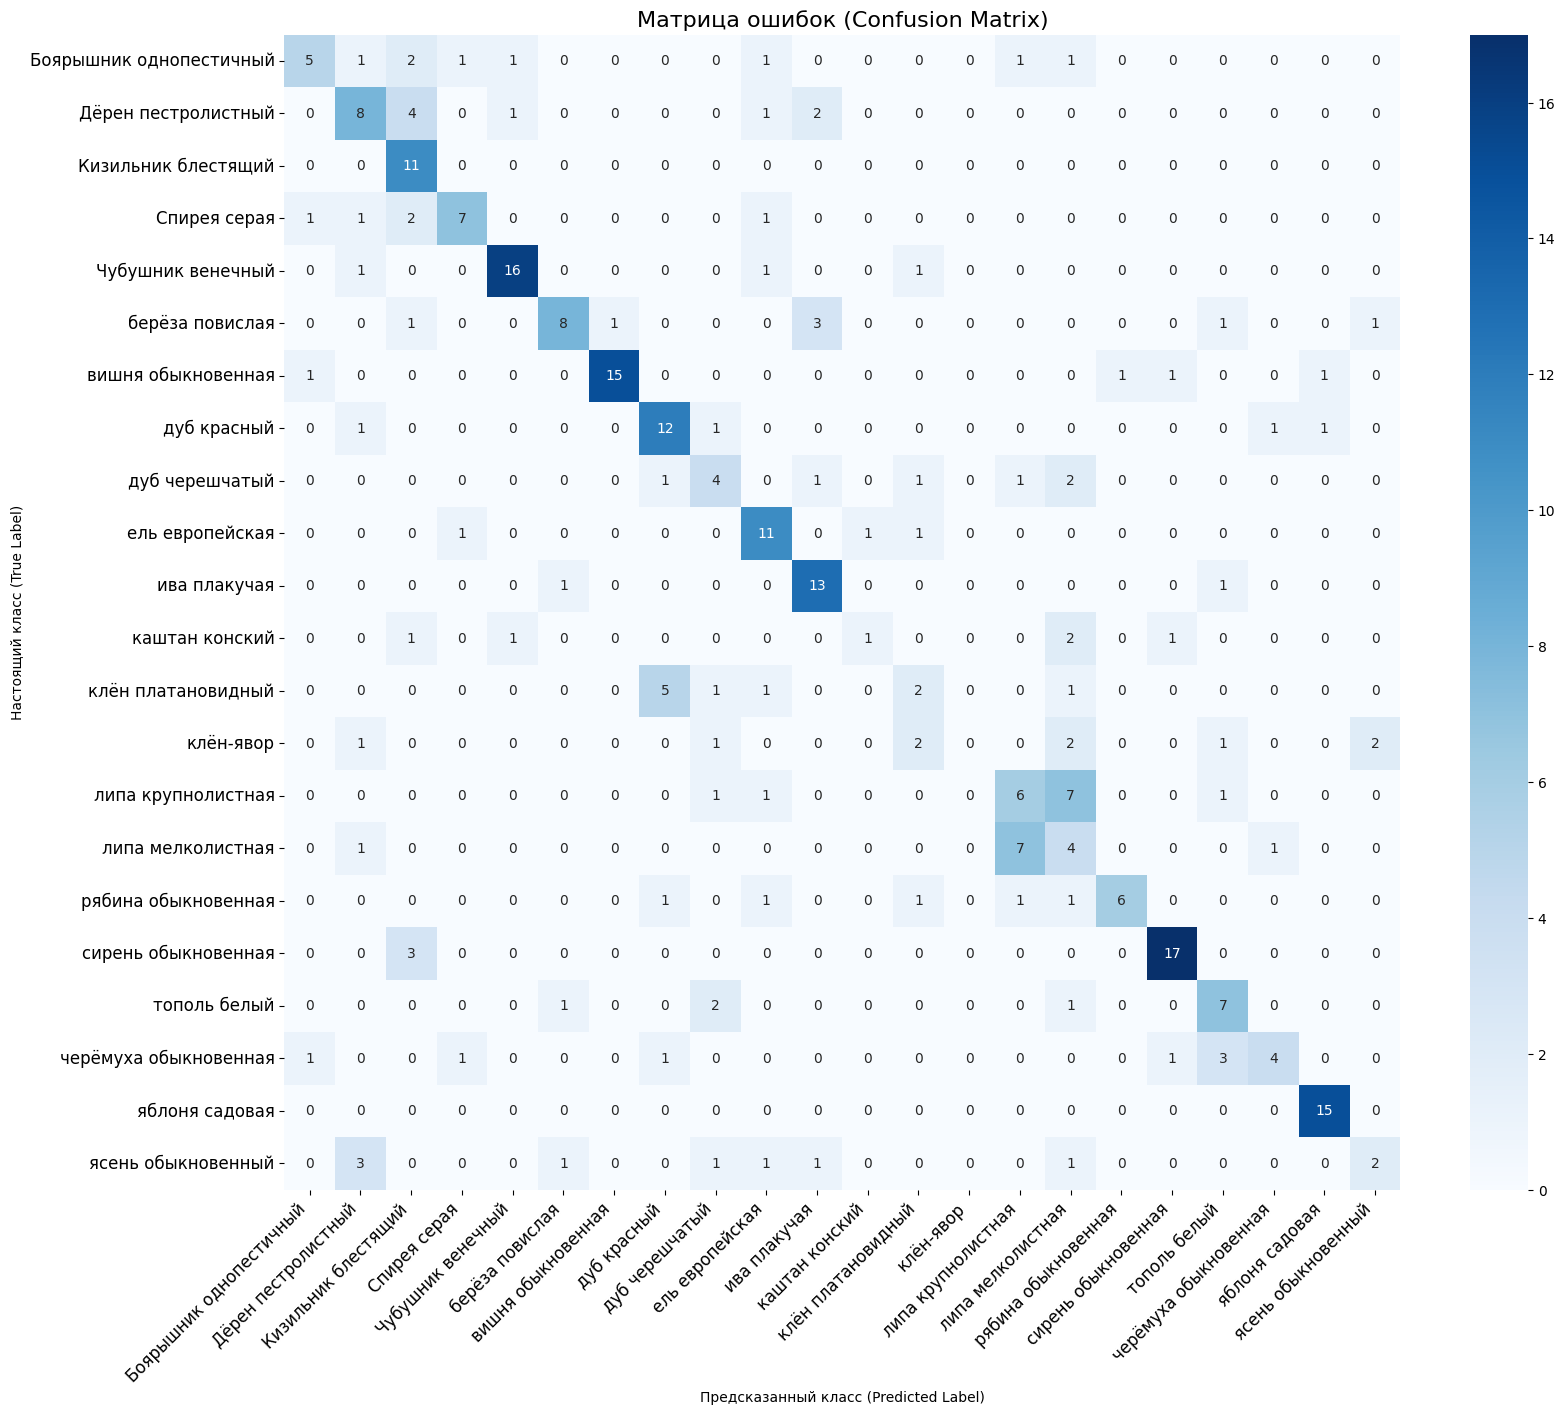

In [28]:
model = models.efficientnet_b2()
num_ftrs = model.classifier[1].in_features
model.classifier = nn.Sequential(
    nn.Dropout(p=DROPOUT_RATE, inplace=True),
    nn.Linear(num_ftrs, num_classes)
)
model = model.to(device)
print("\n--- Построение confusion matrix для лучшей модели на валидационных данных ---")
model.load_state_dict(torch.load('/kaggle/working/best_tree_classifier_b2.pth'))
plot_confusion_matrix(model, dataloaders['val'], class_names, device)